# Experimento 8 · DART y CRNN en la reserva de DatosV4

¿Aporta la fusión de probabilidades una mejora frente a sus dos ramas en las mismas noches del informe? Se reentrenan modelos desde cero sobre 44 noches de Telemetry y 40 de Cassette. La receta de [DART + CRNN](../dart_crnn_mixto.ipynb) queda fijada antes de puntuar. [DatosV4](DatosV4.ipynb) define la reserva y contiene los resultados históricos V4–V7. [Model V5 óptimo](model_v5_optimo.ipynb) documenta el solapamiento del corte original.

Ejecutar en el entorno Python del proyecto con los datos de `datos/` recuperados con DVC. Las cachés locales aceleran el cálculo; el cuaderno no carga pesos entrenados de V8. El control GBDT conserva los hiperparámetros comunes de DART para medir el efecto del modo de boosting con este presupuesto.

In [1]:
import hashlib
import json
import os
import sys
from pathlib import Path

os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "5")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, f1_score

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / ".dvc/config").is_file())
DATA = ROOT / "datos"
AUX = ROOT / "Notebooks/experiments/auxiliares_dart_crnn"
sys.path[:0] = [str(ROOT / "packages/sleep-staging/src"), str(ROOT), str(AUX)]
from crnn_contextual_mixto import entrenar_crnn
from sleep_staging.datasets import read_epoch_labels
from sleep_staging import PreprocessingConfig, PreprocessingPipeline
from sleep_staging.datasets import discover_sleep_cassette_records, discover_sleep_telemetry_records
from sleep_staging.inference.spectral import crnn_probabilities, spectral_input
from sleep_staging.training import create_lightgbm_classifier, load_or_build_supervised_dataset

def leer_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

experimento = DATA / "experimentos/dart_crnn_mixto/dart_666_crnn_27_20261119_191036"
ref = DATA / "referencias/hibrido_v6"
spec = leer_json(DATA / "experimentos/lightgbm_st_sc/experimento.json")
hiper = leer_json(experimento / "hiperparametros.json")
fusion = leer_json(experimento / "fusion.json")
receta = leer_json(experimento / "referencia_seleccion_80_20.json")["contrato"]
hmm = leer_json(ref / "hmm.json")
clases = np.array(spec["classes"])
orden = ["W", "N1", "N2", "N3", "REM"]
assert set(clases) == set(orden)
assert (hiper["iteraciones_dart"], hiper["epocas_crnn"], fusion["porcentaje_dart"]) == (666, 27, 59)
tf.config.experimental.enable_op_determinism()

## Partición por persona y antecedentes de selección

Se emplea el orden lexicográfico de los PSG emparejados. Después de las 40 noches de Cassette de desarrollo, se excluyen todos sus sujetos y se toman las siguientes 20 noches. Se muestran también los cruces con particiones históricas que intervinieron en el diseño.

In [2]:
telemetry = discover_sleep_telemetry_records(DATA / "sleep-telemetry")
cassette = discover_sleep_cassette_records(DATA / "sleep-cassette")
desarrollo = telemetry + cassette[:40]
personas_train = {r.subject_id for r in desarrollo}
prueba = [r for r in cassette[40:] if r.subject_id not in personas_train][:20]
elegidos = {r.subject_id for r in prueba}
assert [r.record_id for r in desarrollo] == hmm["training_records"]
assert (len(desarrollo), len(personas_train), len(prueba), len(elegidos)) == (84, 43, 20, 10)
assert personas_train.isdisjoint(elegidos)
print("Desarrollo (84 noches):", ", ".join(r.record_id for r in desarrollo))
print("Reserva (20 noches):", ", ".join(r.record_id for r in prueba))
print("Cruce con la selección de la receta 80/20:",
      sorted(elegidos & (set(hiper["personas_prueba"]) | set(fusion["personas_prueba"]))))
print("Cruce con el estudio de los parámetros tabulares:",
      sorted(elegidos & (set(spec["train_subjects"]) | set(spec["validation_subjects"]))))

Desarrollo (84 noches): ST7011, ST7012, ST7021, ST7022, ST7041, ST7042, ST7051, ST7052, ST7061, ST7062, ST7071, ST7072, ST7081, ST7082, ST7091, ST7092, ST7101, ST7102, ST7111, ST7112, ST7121, ST7122, ST7131, ST7132, ST7141, ST7142, ST7151, ST7152, ST7161, ST7162, ST7171, ST7172, ST7181, ST7182, ST7191, ST7192, ST7201, ST7202, ST7211, ST7212, ST7221, ST7222, ST7241, ST7242, SC4001, SC4002, SC4011, SC4012, SC4021, SC4022, SC4031, SC4032, SC4041, SC4042, SC4051, SC4052, SC4061, SC4062, SC4071, SC4072, SC4081, SC4082, SC4091, SC4092, SC4101, SC4102, SC4111, SC4112, SC4121, SC4122, SC4131, SC4141, SC4142, SC4151, SC4152, SC4161, SC4162, SC4171, SC4172, SC4181, SC4182, SC4191, SC4192, SC4201
Reserva (20 noches): SC4211, SC4212, SC4221, SC4222, SC4231, SC4232, SC4241, SC4242, SC4251, SC4252, SC4261, SC4262, SC4271, SC4272, SC4281, SC4282, SC4291, SC4292, SC4301, SC4302
Cruce con la selección de la receta 80/20: ['SC429']
Cruce con el estudio de los parámetros tabulares: ['SC426']


## Preparación y ajuste

Se puntúan las cinco etapas anotadas desde 30 minutos antes del primer sueño hasta 30 minutos después del último. En desarrollo solo estas etiquetas contribuyen al ajuste. Cada rama conserva su representación de la noche completa, como en la inferencia retrospectiva. Se fija la semilla 42, con 666 iteraciones de árboles y 27 épocas de red.

In [3]:
def tabla_recortada(registros, cohorte):
    perfil = spec["preprocessing_" + cohorte]
    pipeline = PreprocessingPipeline(PreprocessingConfig(**perfil))
    ds = load_or_build_supervised_dataset(registros, pipeline, DATA / "processed/supervised", verbose=False)
    filas = ds.metadata[["record_id", "subject_id", "epoch_index"]].assign(etapa=ds.labels)
    dormidas = filas.loc[filas.etapa.ne("W")].groupby("record_id").epoch_index.agg(["min", "max"])
    inicio = filas.record_id.map(dormidas["min"]) - 60
    fin = filas.record_id.map(dormidas["max"]) + 60
    conservar = inicio.isna() | filas.epoch_index.between(inicio, fin)
    x = ds.features.loc[conservar].reindex(columns=spec["feature_columns"]).astype("float32")
    return x.reset_index(drop=True), filas.loc[conservar].reset_index(drop=True)

def entrada_espectral(registro):
    with registro.psg_path.open("rb") as archivo:
        huella = hashlib.sha256()
        for bloque in iter(lambda: archivo.read(2**20), b""):
            huella.update(bloque)
    carpeta = DATA / "processed/crnn_espectral" / hiper["receta_espectral"]
    ruta = carpeta / f"{registro.psg_path.stem}-{huella.hexdigest()}.npy"
    if ruta.exists():
        return np.load(ruta, mmap_mode="r", allow_pickle=False)
    return spectral_input(registro.psg_path, receta["canales_crnn"], receta["bandas_hz"])

partes = [tabla_recortada(telemetry, "telemetry")]
partes.extend(tabla_recortada([r], "cassette") for r in cassette[:40])
X_train = pd.concat([x for x, _ in partes], ignore_index=True)
train = pd.concat([m for _, m in partes], ignore_index=True)
del partes
assert len(train) == len(X_train) == hmm["training_epochs"]
assert set(train.record_id) == set(hmm["training_records"])
assert set(train.subject_id).isdisjoint(elegidos)
assert not train.duplicated(["record_id", "epoch_index"]).any()
entradas = {r.record_id: entrada_espectral(r) for r in desarrollo}
print(f"{len(train):,} segmentos de entrenamiento, {X_train.shape[1]:,} variables tabulares.")

85,796 segmentos de entrenamiento, 2,280 variables tabulares.


In [4]:
parametros = dict(spec["parameters"], n_estimators=hiper["iteraciones_dart"], n_jobs=6)
dart = create_lightgbm_classifier(**parametros)
dart.fit(X_train, train.etapa)
np.testing.assert_array_equal(dart.classes_, clases)

params_gbdt = {k: v for k, v in parametros.items() if k not in ("drop_rate", "skip_drop")}
params_gbdt["boosting_type"] = "gbdt"
gbdt = create_lightgbm_classifier(**params_gbdt)
gbdt.fit(X_train, train.etapa)
np.testing.assert_array_equal(gbdt.classes_, clases)
del X_train
red = entrenar_crnn(train, entradas, clases=clases, desfases=receta["desfases"],
                    semilla=42, epocas=hiper["epocas_crnn"])
del entradas

CRNN · 5/27 épocas


CRNN · 10/27 épocas


CRNN · 15/27 épocas


CRNN · 20/27 épocas


CRNN · 25/27 épocas


CRNN · 27/27 épocas


## Predicciones emparejadas con el hipnograma

Se reconstruyen los índices de evaluación a partir del hipnograma original y se verifican por registro antes de puntuar. La fusión usa la media geométrica de probabilidades por clase. El reparto 70/30 se conserva como referencia histórica. El 59/41 es el reparto elegido en el cuaderno principal.

In [5]:
def evaluar_noche(r):
    x, filas = tabla_recortada([r], "cassette")
    espectro = entrada_espectral(r)
    etiquetas = read_epoch_labels(r.hypnogram_path, len(espectro))
    valido = np.isin(etiquetas, orden)
    dormidas = np.flatnonzero(np.isin(etiquetas, orden[1:]))
    if len(dormidas):
        valido[:max(0, dormidas[0] - 60)] = False
        valido[dormidas[-1] + 61:] = False
    idx = np.flatnonzero(valido)
    np.testing.assert_array_equal(filas.epoch_index, idx)
    np.testing.assert_array_equal(filas.etapa, etiquetas[idx])
    p_dart = dart.booster_.predict(x, num_threads=4)
    p_crnn = crnn_probabilities(red, espectro, receta["desfases"], len(clases))[idx]
    for p in (p_dart, p_crnn):
        assert p.shape == (len(idx), 5) and np.isfinite(p).all()
        np.testing.assert_allclose(p.sum(axis=1), 1, atol=1e-5)
    filas["GBDT"] = gbdt.predict(x)
    filas["DART"] = clases[p_dart.argmax(axis=1)]
    filas["CRNN"] = clases[p_crnn.argmax(axis=1)]
    for nombre, peso in [("Fusión 70/30", 0.70), ("Fusión 59/41", fusion["porcentaje_dart"] / 100)]:
        puntajes = peso * np.log(np.maximum(p_dart, 1e-7)) + (1 - peso) * np.log(np.maximum(p_crnn, 1e-7))
        filas[nombre] = clases[puntajes.argmax(axis=1)]
    return filas

resultados = pd.concat([evaluar_noche(r) for r in prueba], ignore_index=True)
assert not resultados.duplicated(["record_id", "epoch_index"]).any()
assert set(resultados.subject_id) == elegidos and len(resultados) == 24101
soporte = resultados.etapa.value_counts().reindex(orden)
np.testing.assert_array_equal(soporte, [7393, 2492, 9064, 1600, 3552])  # DatosV4, informe por clase
print(soporte.to_string())

etapa
W      7393
N1     2492
N2     9064
N3     1600
REM    3552


## Métricas del informe e incertidumbre

Las métricas globales agrupan todas las épocas elegibles. Para estimar la diferencia de F1 macro se remuestrean los diez sujetos con reemplazo 5.000 veces. En cada réplica cada sujeto aporta ambas noches y las predicciones de todos los modelos. Los intervalos describen esta muestra retrospectiva y condicionan sobre los pesos ajustados.

In [2]:
modelos = ["GBDT", "DART", "CRNN", "Fusión 70/30", "Fusión 59/41"]
resumen = []
for nombre in modelos:
    real, pred = resultados.etapa, resultados[nombre]
    por_clase = f1_score(real, pred, labels=orden, average=None, zero_division=0)
    resumen.append({"Modelo": nombre, "Exactitud": accuracy_score(real, pred),
                    "F1 macro": por_clase.mean(), "Kappa": cohen_kappa_score(real, pred),
                    **dict(zip(orden, por_clase))})
tabla = pd.DataFrame(resumen).set_index("Modelo")
print(tabla.to_string(float_format="{:.5f}".format))

matrices = np.array([[confusion_matrix(g.etapa, g[m], labels=orden) for m in modelos]
                     for _, g in resultados.groupby("subject_id", sort=True)])
rng = np.random.default_rng(42)
indices = rng.integers(len(matrices), size=(5000, len(matrices)))
cm = matrices[indices].sum(axis=1)
den = cm.sum(axis=-1) + cm.sum(axis=-2)
f1 = np.divide(2 * np.diagonal(cm, axis1=-2, axis2=-1), den,
               out=np.zeros(den.shape, dtype=float), where=den != 0).mean(axis=-1)
for a, b in [("DART", "GBDT"), ("Fusión 59/41", "DART"), ("Fusión 59/41", "GBDT"),
             ("Fusión 59/41", "CRNN"),
             ("Fusión 59/41", "Fusión 70/30")]:
    delta = tabla.at[a, "F1 macro"] - tabla.at[b, "F1 macro"]
    lo, hi = np.quantile(f1[:, modelos.index(a)] - f1[:, modelos.index(b)], [0.025, 0.975])
    print(f"{a} menos {b}: {delta:+.5f} (IC 95 % [{lo:+.5f}, {hi:+.5f}])")

              Exactitud  F1 macro   Kappa       W      N1      N2      N3     REM
Modelo                                                                           
GBDT            0.83416   0.78288 0.77190 0.92428 0.47641 0.85031 0.80984 0.85356
DART            0.82316   0.77654 0.75972 0.92275 0.48586 0.83760 0.79053 0.84595
CRNN            0.81204   0.75288 0.74403 0.92386 0.45794 0.82481 0.70461 0.85317
Fusión 70/30    0.83212   0.78171 0.77137 0.92998 0.49950 0.84475 0.76989 0.86444
Fusión 59/41    0.83109   0.77907 0.76986 0.93124 0.49595 0.84374 0.76228 0.86213
DART menos GBDT: -0.00635 (IC 95 % [-0.01117, -0.00104])
Fusión 59/41 menos DART: +0.00253 (IC 95 % [-0.00605, +0.01216])
Fusión 59/41 menos GBDT: -0.00381 (IC 95 % [-0.01168, +0.00367])
Fusión 59/41 menos CRNN: +0.02619 (IC 95 % [+0.01787, +0.03410])
Fusión 59/41 menos Fusión 70/30: -0.00264 (IC 95 % [-0.00454, -0.00062])


## Errores del modelo elegido

La matriz presenta el porcentaje de épocas de cada estadio real asignado a cada predicción. El soporte se conserva junto al nombre del estadio. Se guarda la figura que usa el manuscrito.

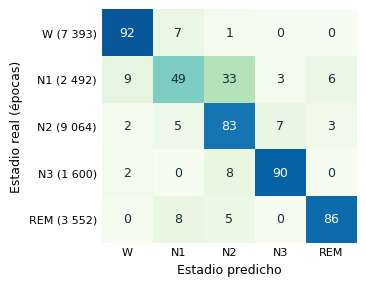

        W    N1    N2    N3   REM
W    6826   494    52     8    13
N1    224  1224   820    63   161
N2    165   442  7484   659   314
N3     38     2   125  1435     0
REM    14   282   195     0  3061


In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

orden_figura = ["W", "N1", "N2", "N3", "REM"]
conteos = confusion_matrix(resultados.etapa, resultados["Fusión 59/41"], labels=orden_figura)
soportes = conteos.sum(axis=1)
porcentajes = 100 * conteos / soportes[:, None]
fig, ax = plt.subplots(figsize=(3.55, 2.75), layout="constrained")
ax.imshow(porcentajes, cmap="GnBu", vmin=0, vmax=100, aspect="auto")
for (fila, col), porcentaje in np.ndenumerate(porcentajes):
    ax.text(col, fila, f"{porcentaje:.0f}", ha="center", va="center", fontsize=9,
            color="white" if porcentaje >= 62 else "#112d38")
ax.set(xticks=range(5), xticklabels=orden_figura, yticks=range(5),
       yticklabels=[f"{etapa} ({n:,})".replace(",", " ") for etapa, n in zip(orden_figura, soportes)],
       xlabel="Estadio predicho", ylabel="Estadio real (épocas)")
ax.tick_params(length=0, labelsize=8)
ax.xaxis.label.set_size(9)
ax.yaxis.label.set_size(9)
for borde in ax.spines.values():
    borde.set_visible(False)
destino = ROOT / "docs/versionPreFinal/EntregaFinal_v3_20261121/matriz_v8_fusion.png"
fig.savefig(destino, dpi=300, bbox_inches="tight", pad_inches=0.04)
plt.show()
print(pd.DataFrame(conteos, index=orden_figura, columns=orden_figura).to_string())

## Verificación de las cifras históricas

La primera tabla lee las líneas de métricas de las ejecuciones guardadas de DatosV4. La segunda recalcula las métricas sobre las probabilidades archivadas de la selección mixta de 20 personas. Aquí se conservan todas las épocas anotadas de esas personas, como en el notebook mixto original.

In [4]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score

raiz = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / ".dvc/config").is_file())
anterior = json.loads((raiz / "Notebooks/experiments/DatosV4.ipynb").read_text(encoding="utf-8"))
patron = re.compile(r"✅ (.+?)\s+\| Acc: ([.\d]+) \| F1-M: ([.\d]+) \| Kappa: ([.\d]+) \| F1-N1: ([.\d]+)")
filas_historicas = []
for celda in anterior["cells"]:
    for salida in celda.get("outputs", []):
        for nombre, *valores in patron.findall("".join(salida.get("text", []))):
            filas_historicas.append([nombre.strip(), *map(float, valores)])
historico = pd.DataFrame(filas_historicas, columns=["Modelo", "Exactitud", "F1 macro", "Kappa", "F1 N1"])
assert len(historico) == historico.Modelo.nunique() == 14
print(historico.to_string(index=False))

archivo = raiz / "datos/experimentos/dart_crnn_mixto/dart_666_crnn_27_20261119_191036"
with np.load(archivo / "predicciones_80_20.npz", allow_pickle=False) as datos:
    y = datos["clase_real"]
    assert len(y) == 92369 and len(np.unique(datos["registro"])) == 39
    assert list(datos["clases"]) == ["N1", "N2", "N3", "REM", "W"]
    log_dart = np.log(np.maximum(datos["dart"], 1e-7))
    log_crnn = np.log(np.maximum(datos["crnn"], 1e-7))
seleccion = []
for porcentaje in [0, 100, 70, 59]:
    peso = porcentaje / 100
    pred = (peso * log_dart + (1 - peso) * log_crnn).argmax(axis=1)
    seleccion.append([porcentaje, accuracy_score(y, pred),
                      f1_score(y, pred, labels=range(5), average="macro"), cohen_kappa_score(y, pred)])
seleccion = pd.DataFrame(seleccion, columns=["% DART", "Exactitud", "F1 macro", "Kappa"])
print(seleccion.to_string(index=False, float_format="{:.5f}".format))

                                   Modelo  Exactitud  F1 macro  Kappa  F1 N1
                V4 (CRNN Pura - Baseline)     0.6724    0.6158 0.5728 0.3461
            V4 (Ensamble LightGBM Simple)     0.6961    0.6401 0.5969 0.3755
             V4 (LGBM Telemetry+Cassette)     0.7582    0.6822 0.6690 0.3862
       V5 Base (CRNN + Data Augmentation)     0.7486    0.6833 0.6587 0.3928
                       V5 Base (LightGBM)     0.7737    0.7093 0.6869 0.4068
     V5 Óptimo (CRNN + Data Augmentation)     0.7564    0.6912 0.6690 0.4067
              V5 Óptimo (LightGBM Optuna)     0.7818    0.7137 0.6984 0.4066
                V6 Fase B (Contexto 192D)     0.7838    0.7139 0.7005 0.4082
                V6 Fase C (Suavizado HMM)     0.7874    0.7138 0.7045 0.3876
     V7 Exp 3 (+ Pesos Agresivo_N1, 528D)     0.7971    0.7286 0.7188 0.4144
         V7 Exp 4 (Exp 3 + Auditoría HMM)     0.7993    0.7260 0.7211 0.3933
                    V6 Fase D (TTA + HMM)     0.7891    0.7145 0.7065 0.3821